In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import numpy as np
import pandas as pd

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import statsmodels.api as sm

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, 
    recall_score, f1_score, roc_curve, auc, classification_report
)

from scipy.stats import shapiro, levene, f_oneway, kruskal

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from imblearn.over_sampling import SMOTE
from collections import Counter

import os

# Загрузка датасета + краткий обзор (Overview)

In [47]:
path = f'{os.getcwd()}/course_dataset/Extended_Employee_Performance_and_Productivity_Data.csv'

df = pd.read_csv(path)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Employee_ID                  100000 non-null  int64  
 1   Department                   100000 non-null  str    
 2   Gender                       100000 non-null  str    
 3   Age                          100000 non-null  int64  
 4   Job_Title                    100000 non-null  str    
 5   Hire_Date                    100000 non-null  str    
 6   Years_At_Company             100000 non-null  int64  
 7   Education_Level              100000 non-null  str    
 8   Performance_Score            100000 non-null  int64  
 9   Monthly_Salary               100000 non-null  float64
 10  Work_Hours_Per_Week          100000 non-null  int64  
 11  Projects_Handled             100000 non-null  int64  
 12  Overtime_Hours               100000 non-null  int64  
 13  Sick_Days  

In [48]:
df.describe()

,Employee_ID,Age,Years_At_Company,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,41.029410,4.476070,2.995430,6403.211000,44.956950,24.431170,14.514930,7.008550,50.090500,10.013560,49.506060,0.999720,2.999088
std,28867.657797,11.244121,2.869336,1.414726,1372.508717,8.942003,14.469584,8.664026,4.331591,35.351157,5.495405,28.890383,0.815872,1.150719
min,1.000000,22.000000,0.000000,1.000000,3850.000000,30.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000
25%,25000.750000,31.000000,2.000000,2.000000,5250.000000,37.000000,12.000000,7.000000,3.000000,25.000000,5.000000,25.000000,0.000000,2.010000
50%,50000.500000,41.000000,4.000000,3.000000,6500.000000,45.000000,24.000000,15.000000,7.000000,50.000000,10.000000,49.000000,1.000000,3.000000
75%,75000.250000,51.000000,7.000000,4.000000,7500.000000,53.000000,37.000000,22.000000,11.000000,75.000000,15.000000,75.000000,2.000000,3.990000
max,100000.000000,60.000000,10.000000,5.000000,9000.000000,60.000000,49.000000,29.000000,14.000000,100.000000,19.000000,99.000000,2.000000,5.000000


In [49]:
print(f"Число дубликатов: {df.duplicated().sum()}")
print(f"Число пропущенных значений: {df.isna().sum().sum()}")

Число дубликатов: 0
Число пропущенных значений: 0


In [50]:
df.head(5)

,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.0,33,32,22,2,0,14,66,0,2.63,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.0,34,34,13,14,100,12,61,2,1.72,False
2,3,Finance,Male,55,Specialist,2015-10-26 08:03:05.556036,8,High School,3,5850.0,37,27,6,3,50,10,1,0,3.17,False
3,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800.0,52,10,28,12,100,10,0,1,1.86,False
4,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800.0,38,11,29,13,100,15,9,1,1.25,False


In [51]:
NUMERIC_FEATURES = [
    'Age', 'Years_At_Company', 'Performance_Score', 'Monthly_Salary',
    'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours',
    'Sick_Days', 'Remote_Work_Frequency', 'Team_Size',
    'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score'
]
NOMINAL_FEATURES = [
    'Department', 'Gender', 'Job_Title', 'Education_Level'
]

REGRESSION_TARGET = 'Employee_Satisfaction_Score'
CLASSIFICATION_TARGET = 'Resigned'
MAIN_FEATURE = 'Monthly_Salary'

# Задание №1. Первичная обработка данных

In [52]:
# Удаление незначащих признаков
df = df.drop(columns=['Employee_ID'])

In [53]:
# Преобразование в datetime (некорректные значения станут NaT)
df['Hire_Date'] = pd.to_datetime(df['Hire_Date'], errors='coerce')

# Сортировка по дате и сброс индекса
df = df.sort_values(by='Hire_Date').reset_index(drop=True)

print(f"Количество некорректных дат: {df['Hire_Date'].isna().sum()}")

Количество некорректных дат: 0


In [54]:
def plot_boxplots(df, columns, n_rows=1, figsize=(12, 6), rotation=45):
    n_cols = len(columns)
    fig, axes = plt.subplots(n_rows, len(columns) // n_rows, figsize=figsize)
    
    if n_cols == 1:
        axes = [axes]
    
    for ax, col in zip(axes.flatten(), columns):
        ax.boxplot(df[col].dropna(), patch_artist=True, 
                   boxprops=dict(facecolor='#AEC7E8'),
                   medianprops=dict(color='red', linewidth=2))
        ax.set_title(col, fontsize=12)
        ax.set_ylabel('Value')
        ax.grid(True, axis='y', linestyle='--', alpha=0.3)
        ax.tick_params(axis='x', rotation=rotation)

    plt.tight_layout()
    plt.show()

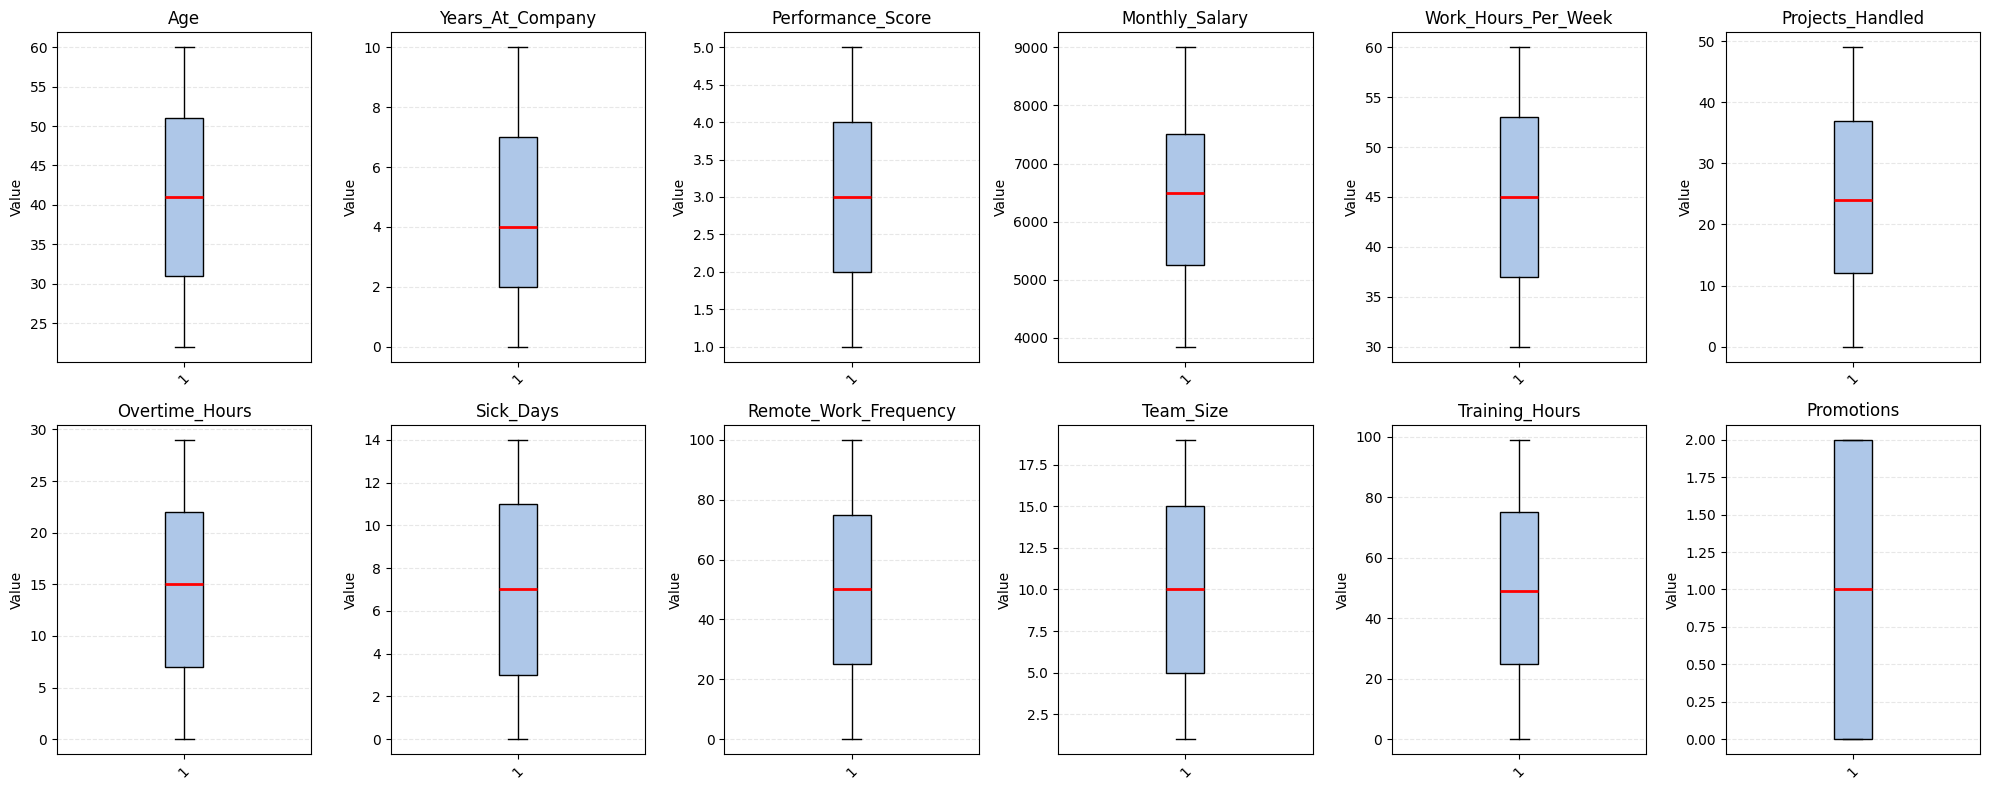

In [55]:
plot_boxplots(df, NUMERIC_FEATURES, n_rows=2, figsize=(20, 8))

In [56]:
def plot_bars(ax_flat, df, cols):
    for ax, col in zip(ax_flat, cols):
        df[col].value_counts().plot.bar(ax=ax, title=col)
        ax.tick_params(axis='x', rotation=30)
        ax.set_xlabel(None)

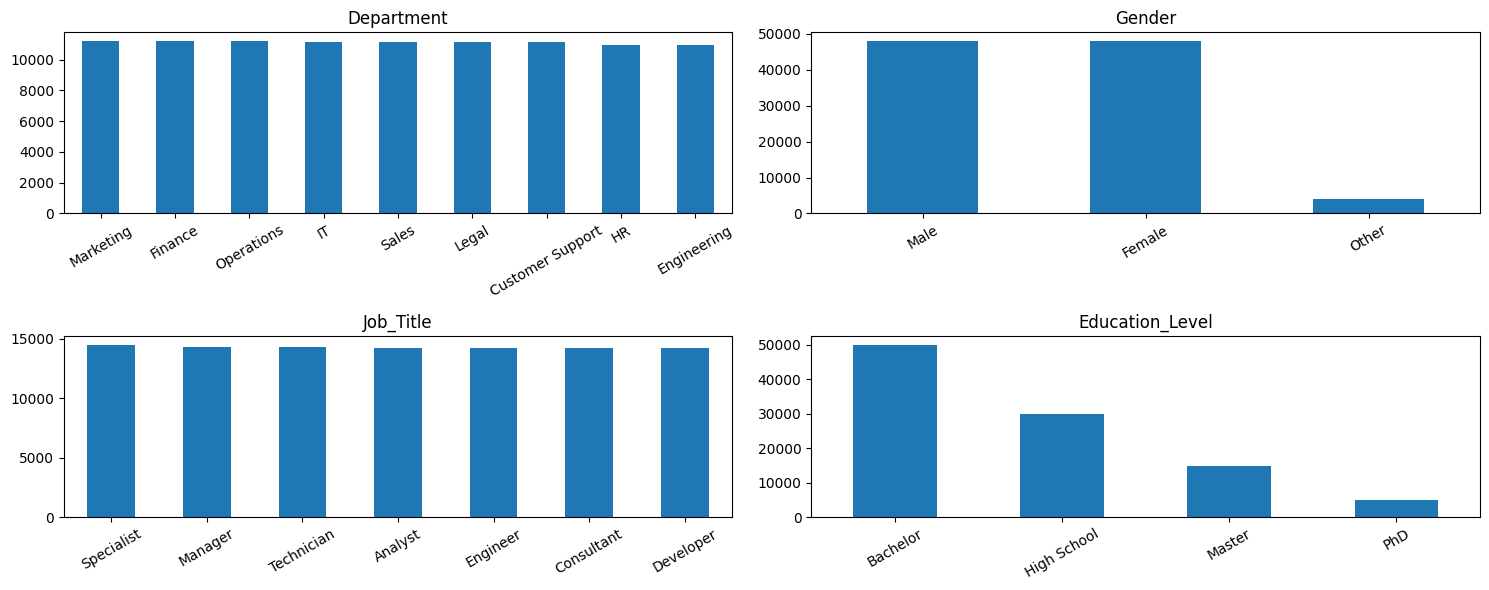

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(15, 6))
plot_bars(axes.flatten(), df, NOMINAL_FEATURES)
plt.tight_layout()
plt.show()

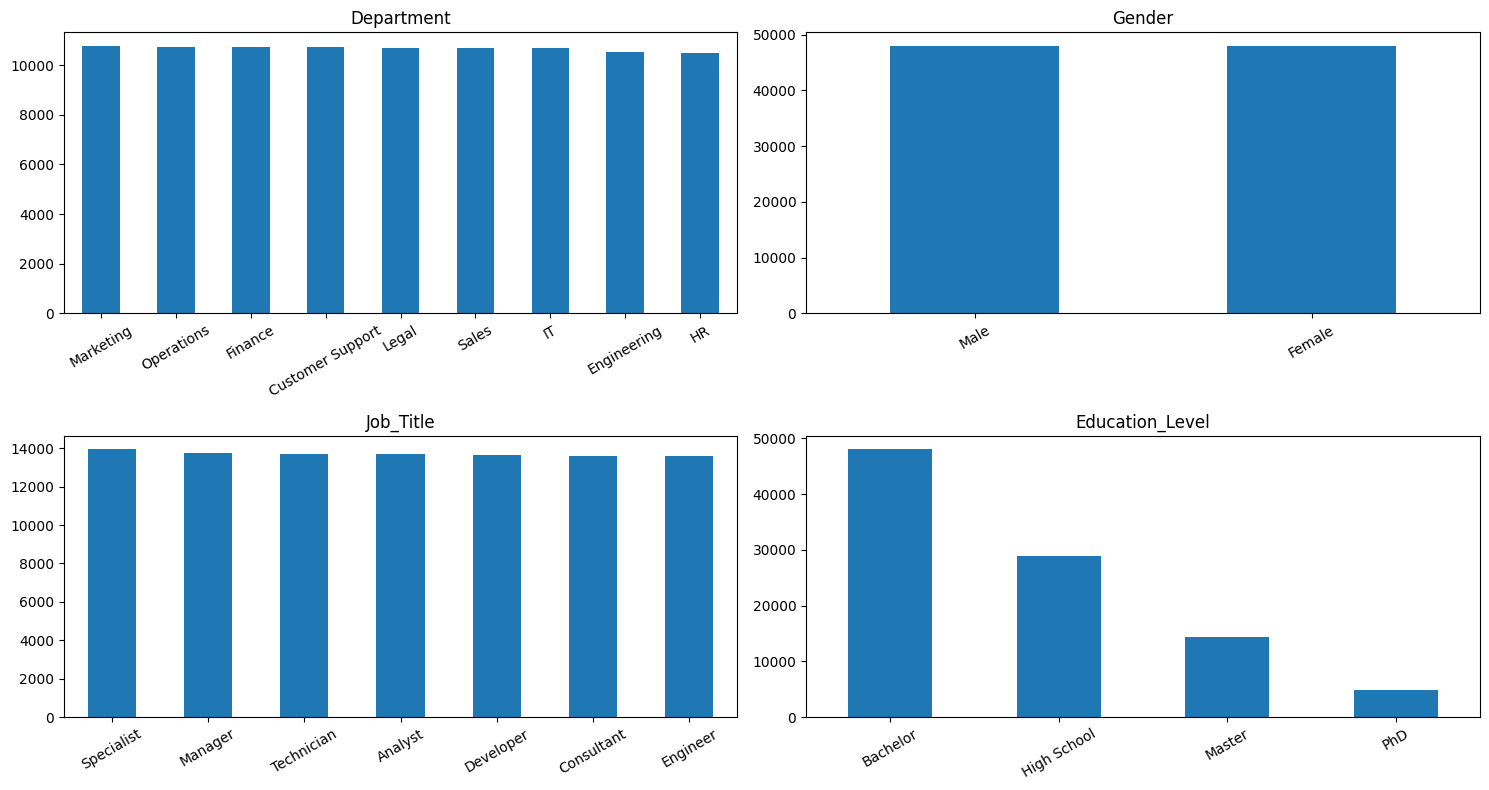

In [58]:
# Удаляем непонятный гендер
df = df[df['Gender'] != 'Other'].reset_index(drop=True)

# Визуализация результатов
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
plot_bars(axes.flatten(), df, NOMINAL_FEATURES)
plt.tight_layout()
plt.show()

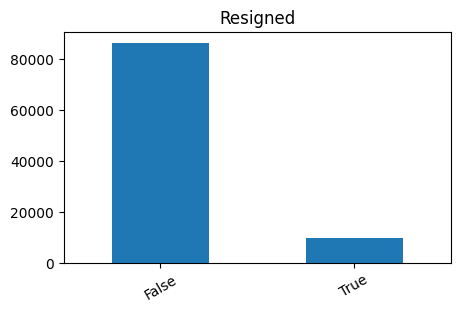

In [59]:
fig, ax = plt.subplots(figsize=(5, 3))
df[CLASSIFICATION_TARGET].value_counts().head(10).plot.bar(ax=ax, title=f"{CLASSIFICATION_TARGET}")
ax.tick_params(axis='x', rotation=30)
ax.set_xlabel(None)
plt.show()

# Задание №2. Визуализация и описательная статистика

In [62]:
def plot_feature_histogram(ax, df, feature, bins=30, y_scale='linear'):
    n_bins = min(bins, df[feature].nunique())
    
    ax.set_yscale(y_scale)
    ax.hist(df[feature], bins=n_bins, edgecolor='black', alpha=0.7)
    ax.set_title(feature, fontsize=12)
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')
    ax.grid(True, linestyle='--', alpha=0.3)

def plot_feature_histogram_with_classes(ax, df, feature, target_col, bins=30, y_scale='linear'):
    # Построение гистограмм для каждого класса целевой переменной
    n_bins = min(bins, df[feature].nunique())
    ax.set_yscale(y_scale)
    
    for class_val in sorted(df[target_col].unique()):
        ax.hist(df[df[target_col] == class_val][feature], bins=n_bins, 
                edgecolor='black', alpha=0.7, label=f'{class_val}')
    
    ax.set_title(feature, fontsize=12)
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.legend(title=target_col)

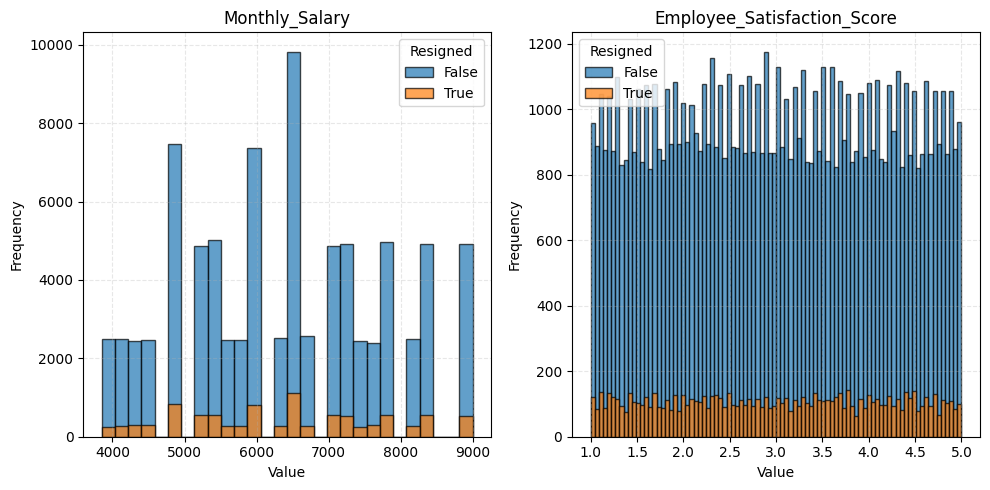

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for idx, feature in enumerate([MAIN_FEATURE] + [REGRESSION_TARGET]):
    plot_feature_histogram_with_classes(axes[idx], df, feature, CLASSIFICATION_TARGET, bins=90, y_scale='linear')

plt.tight_layout()
plt.show()

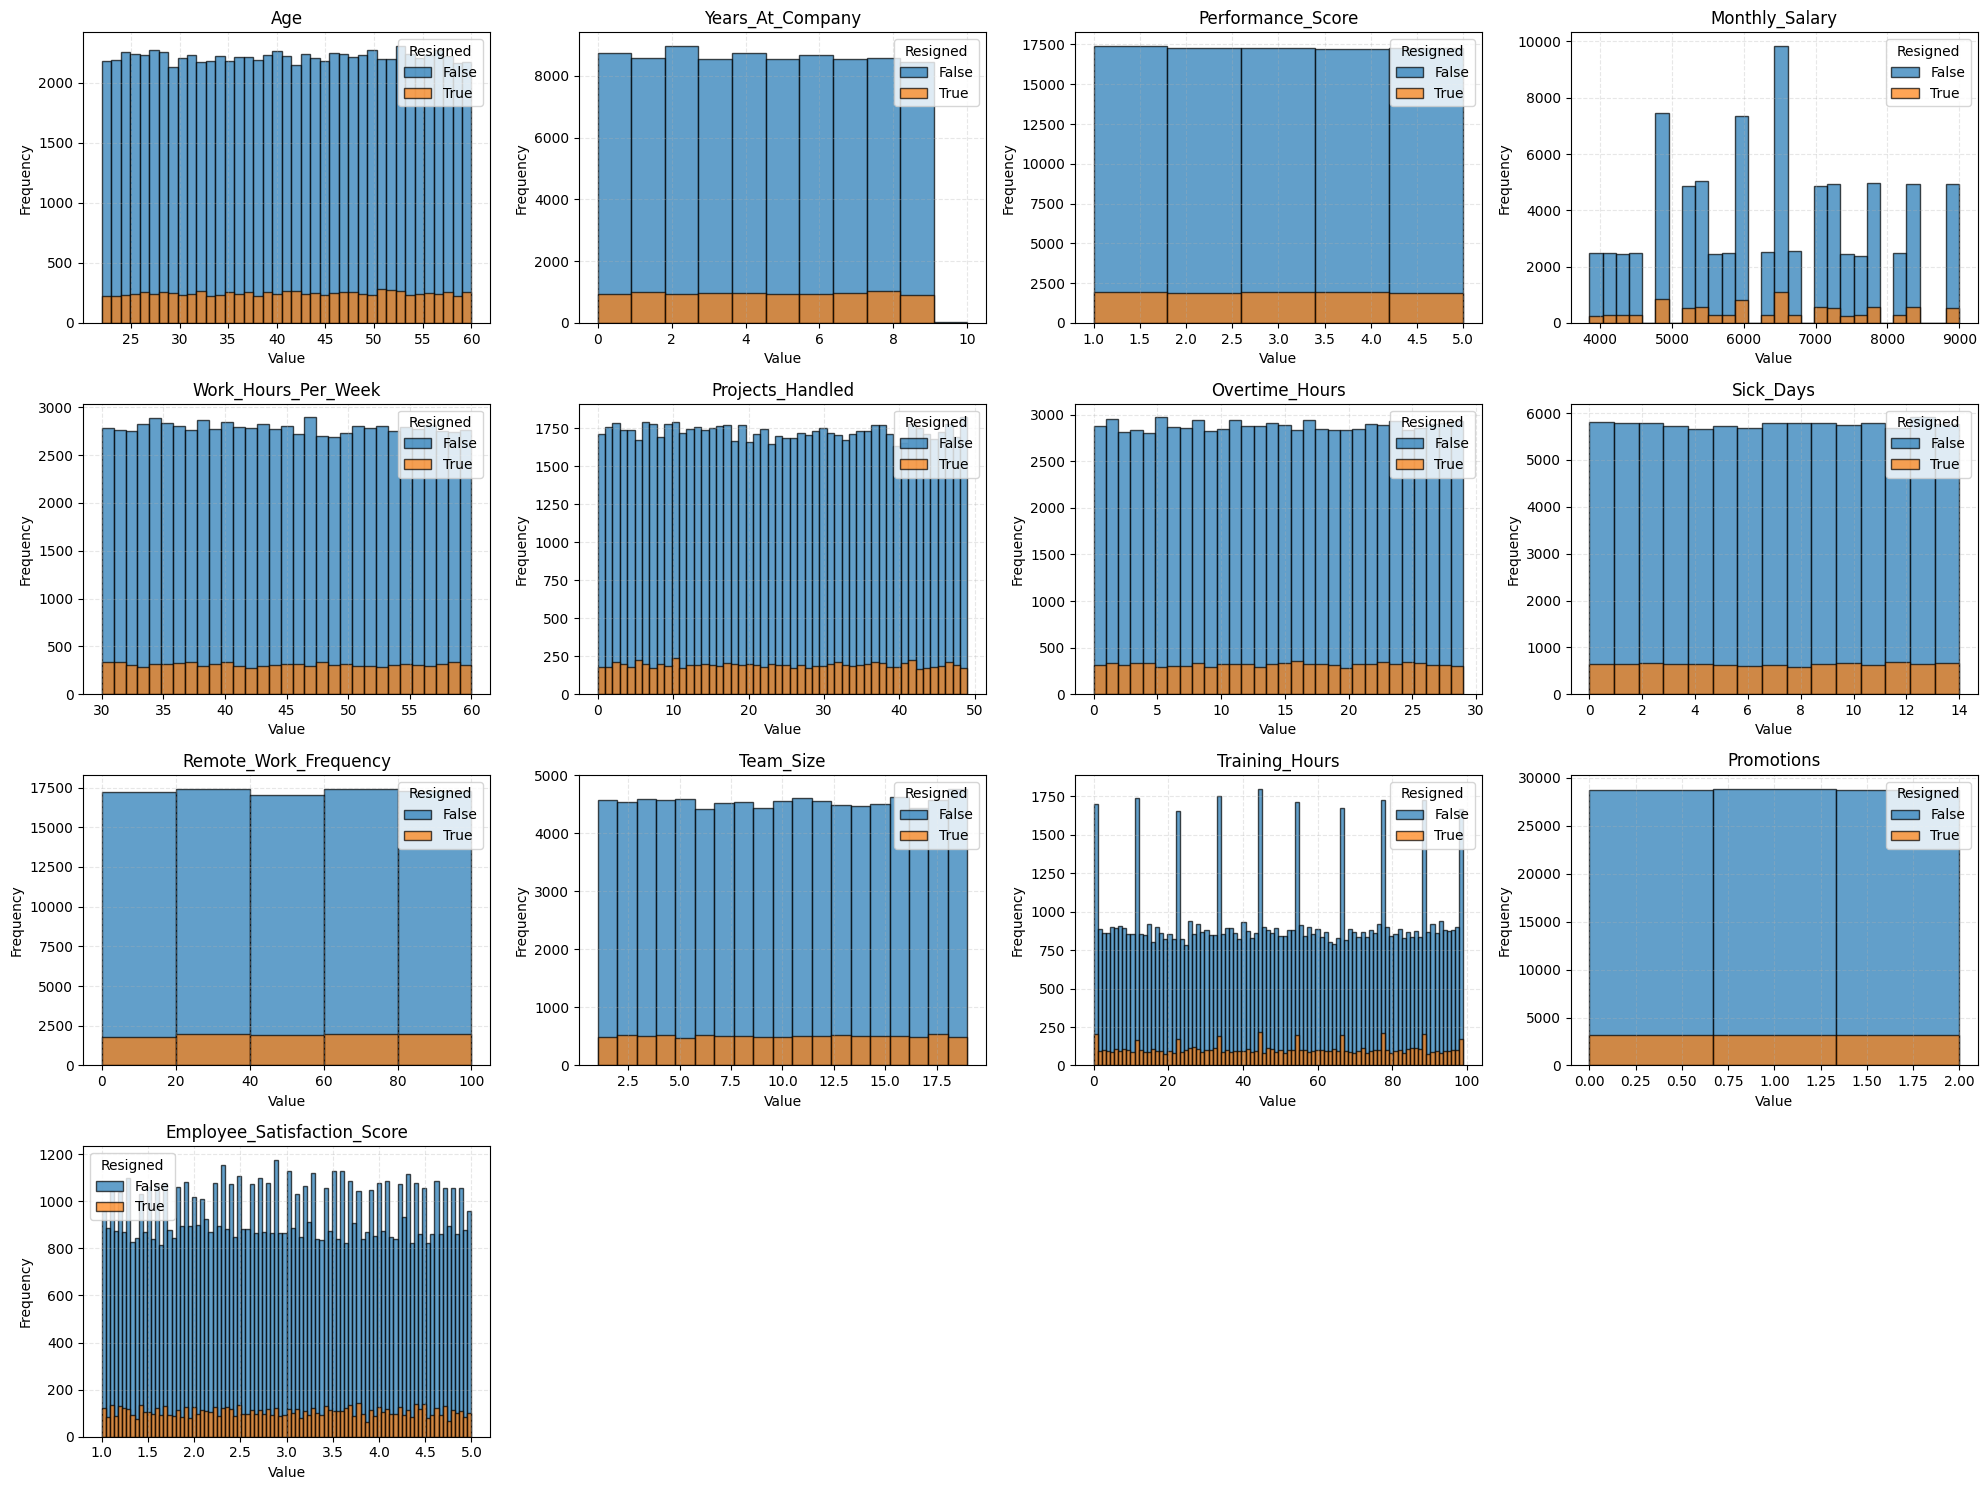

In [79]:
fig, axes = plt.subplots(4, 4, figsize=(20, 15))
axes_flat = axes.flatten()

for idx, feature in enumerate(NUMERIC_FEATURES):
    plot_feature_histogram_with_classes(axes_flat[idx], df, feature, CLASSIFICATION_TARGET, bins=90, y_scale='linear')
for idx in range(len(NUMERIC_FEATURES), 4*4):
    fig.delaxes(axes_flat[idx])

plt.tight_layout()
plt.show()

In [64]:
def stats_by_class(df, cols, target_col):
    # Возвращает mean/median/std для всей выборки и по классам
    stats = ['mean', 'median', 'std']
    overall = df[cols].agg(stats).assign(class_='All').reset_index().rename(columns={'index': 'metric'})
    by_class = df.groupby(target_col)[cols].agg(stats).stack().reset_index().rename(columns={'level_1': 'metric', target_col: 'class_'})
    return pd.concat([overall, by_class], ignore_index=True).pivot(index='metric', columns='class_', values=cols)

In [65]:
stats_by_class(df, [MAIN_FEATURE] + [REGRESSION_TARGET], CLASSIFICATION_TARGET)

Monthly_Salary                           Employee_Satisfaction_Score  \
class_          False         True          All                       False   
metric                                                                        
mean      6403.548242  6395.417230  6402.733464                    3.000679   
median    6500.000000  6500.000000  6500.000000                    3.000000   
std       1372.157709  1368.680766  1371.804754                    1.150900   

                            
class_      True       All  
metric                      
mean    2.989418  2.999551  
median  2.990000  3.000000  
std     1.152046  1.151014

In [ ]:
def analyze_features(df, col1, col2, target_col):
    # Медиана для col1
    median = df[col1].median()
    below = df[df[col1] <= median]
    above = df[df[col1] > median]
    
    print(f"=== {col1} ===")
    print(f"Медиана: {median:.2f}")
    print(f"Ниже медианы: n={len(below)}, mean={below[col1].mean():.2f}, std={below[col1].std():.2f}")
    print(f"Выше медианы: n={len(above)}, mean={above[col1].mean():.2f}, std={above[col1].std():.2f}")
    
    # Визуализация
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    
    # 1. Гистограммы col1
    axes[0, 0].hist(below[col1], bins=20, alpha=0.7, label='Below', edgecolor='black')
    axes[0, 0].hist(above[col1], bins=20, alpha=0.7, label='Above', edgecolor='black')
    axes[0, 0].set_title(f'Histogram: {col1}')
    axes[0, 0].legend()
    
    # 2. Boxplot col1 по классам target
    sns.boxplot(data=df, x=target_col, y=col1, ax=axes[0, 1])
    axes[0, 1].set_title(f'Boxplot: {col1} by {target_col}')
    
    # 3. Scatterplot: n vs m с раскраской по target
    sns.scatterplot(data=df, x=col1, y=col2, hue=target_col, alpha=0.6, ax=axes[0, 2])
    axes[0, 2].set_title(f'Scatter: {col1} vs {col2}')
    
    # 4. Гистограммы col2
    axes[1, 0].hist(below[col2], bins=20, alpha=0.7, label='Below', edgecolor='black')
    axes[1, 0].hist(above[col2], bins=20, alpha=0.7, label='Above', edgecolor='black')
    axes[1, 0].set_title(f'Histogram: {col2}')
    axes[1, 0].legend()
    
    # 5. Boxplot col2 по классам target
    sns.boxplot(data=df, x=target_col, y=col2, ax=axes[1, 1])
    axes[1, 1].set_title(f'Boxplot: {col2} by {target_col}')
    
    # 6. Scatterplot: col2 vs col1 (обратный)
    sns.scatterplot(data=df, x=col2, y=col1, hue=target_col, alpha=0.6, ax=axes[1, 2])
    axes[1, 2].set_title(f'Scatter: {col2} vs {col1}')
    
    plt.tight_layout()
    plt.show()

=== Monthly_Salary ===
Медиана: 6500.00
Ниже медианы: n=49548, mean=5293.83, std=732.88
Выше медианы: n=46484, mean=7584.73, std=779.34


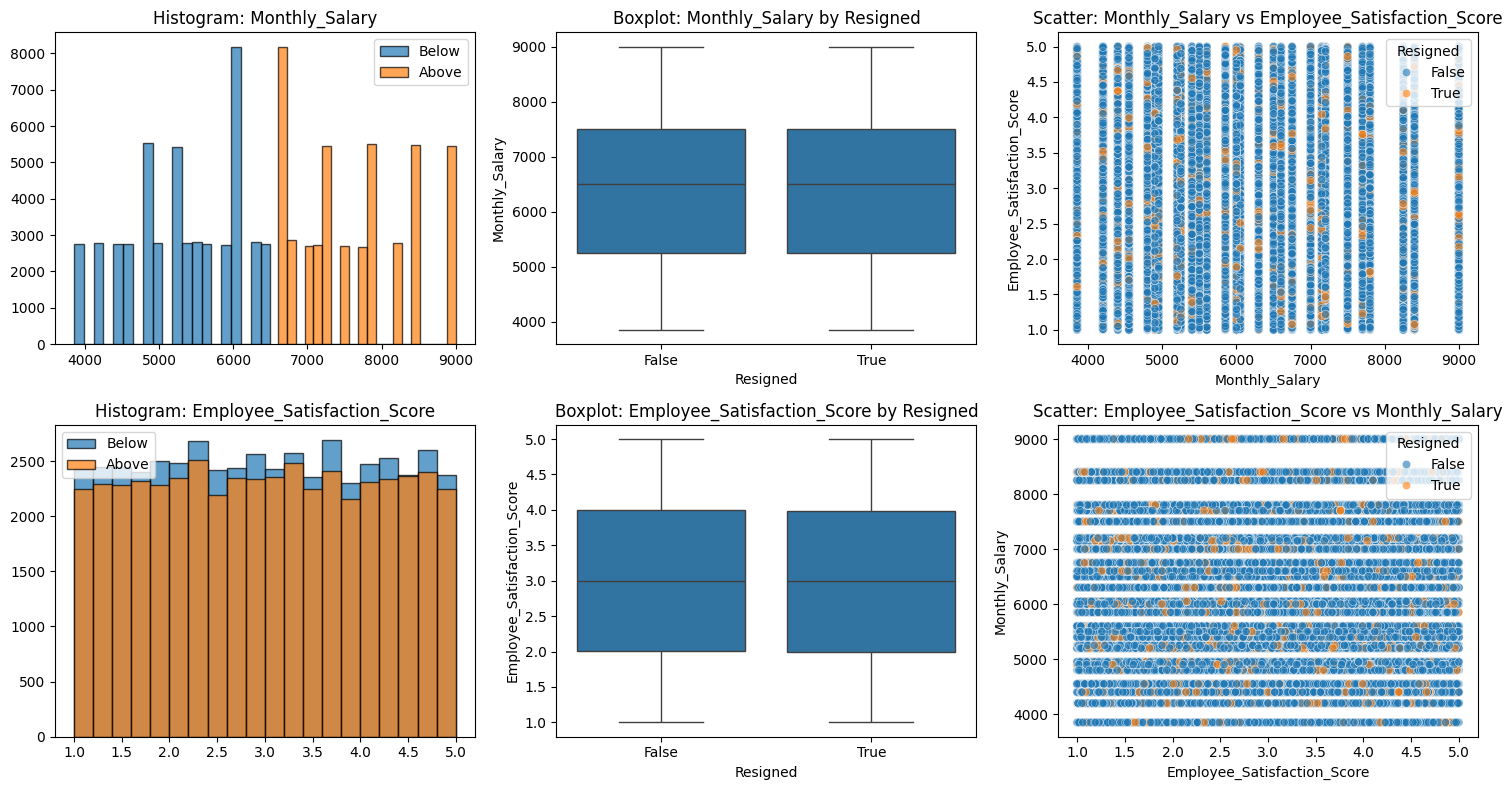

In [67]:
analyze_features(df, MAIN_FEATURE, REGRESSION_TARGET, CLASSIFICATION_TARGET)

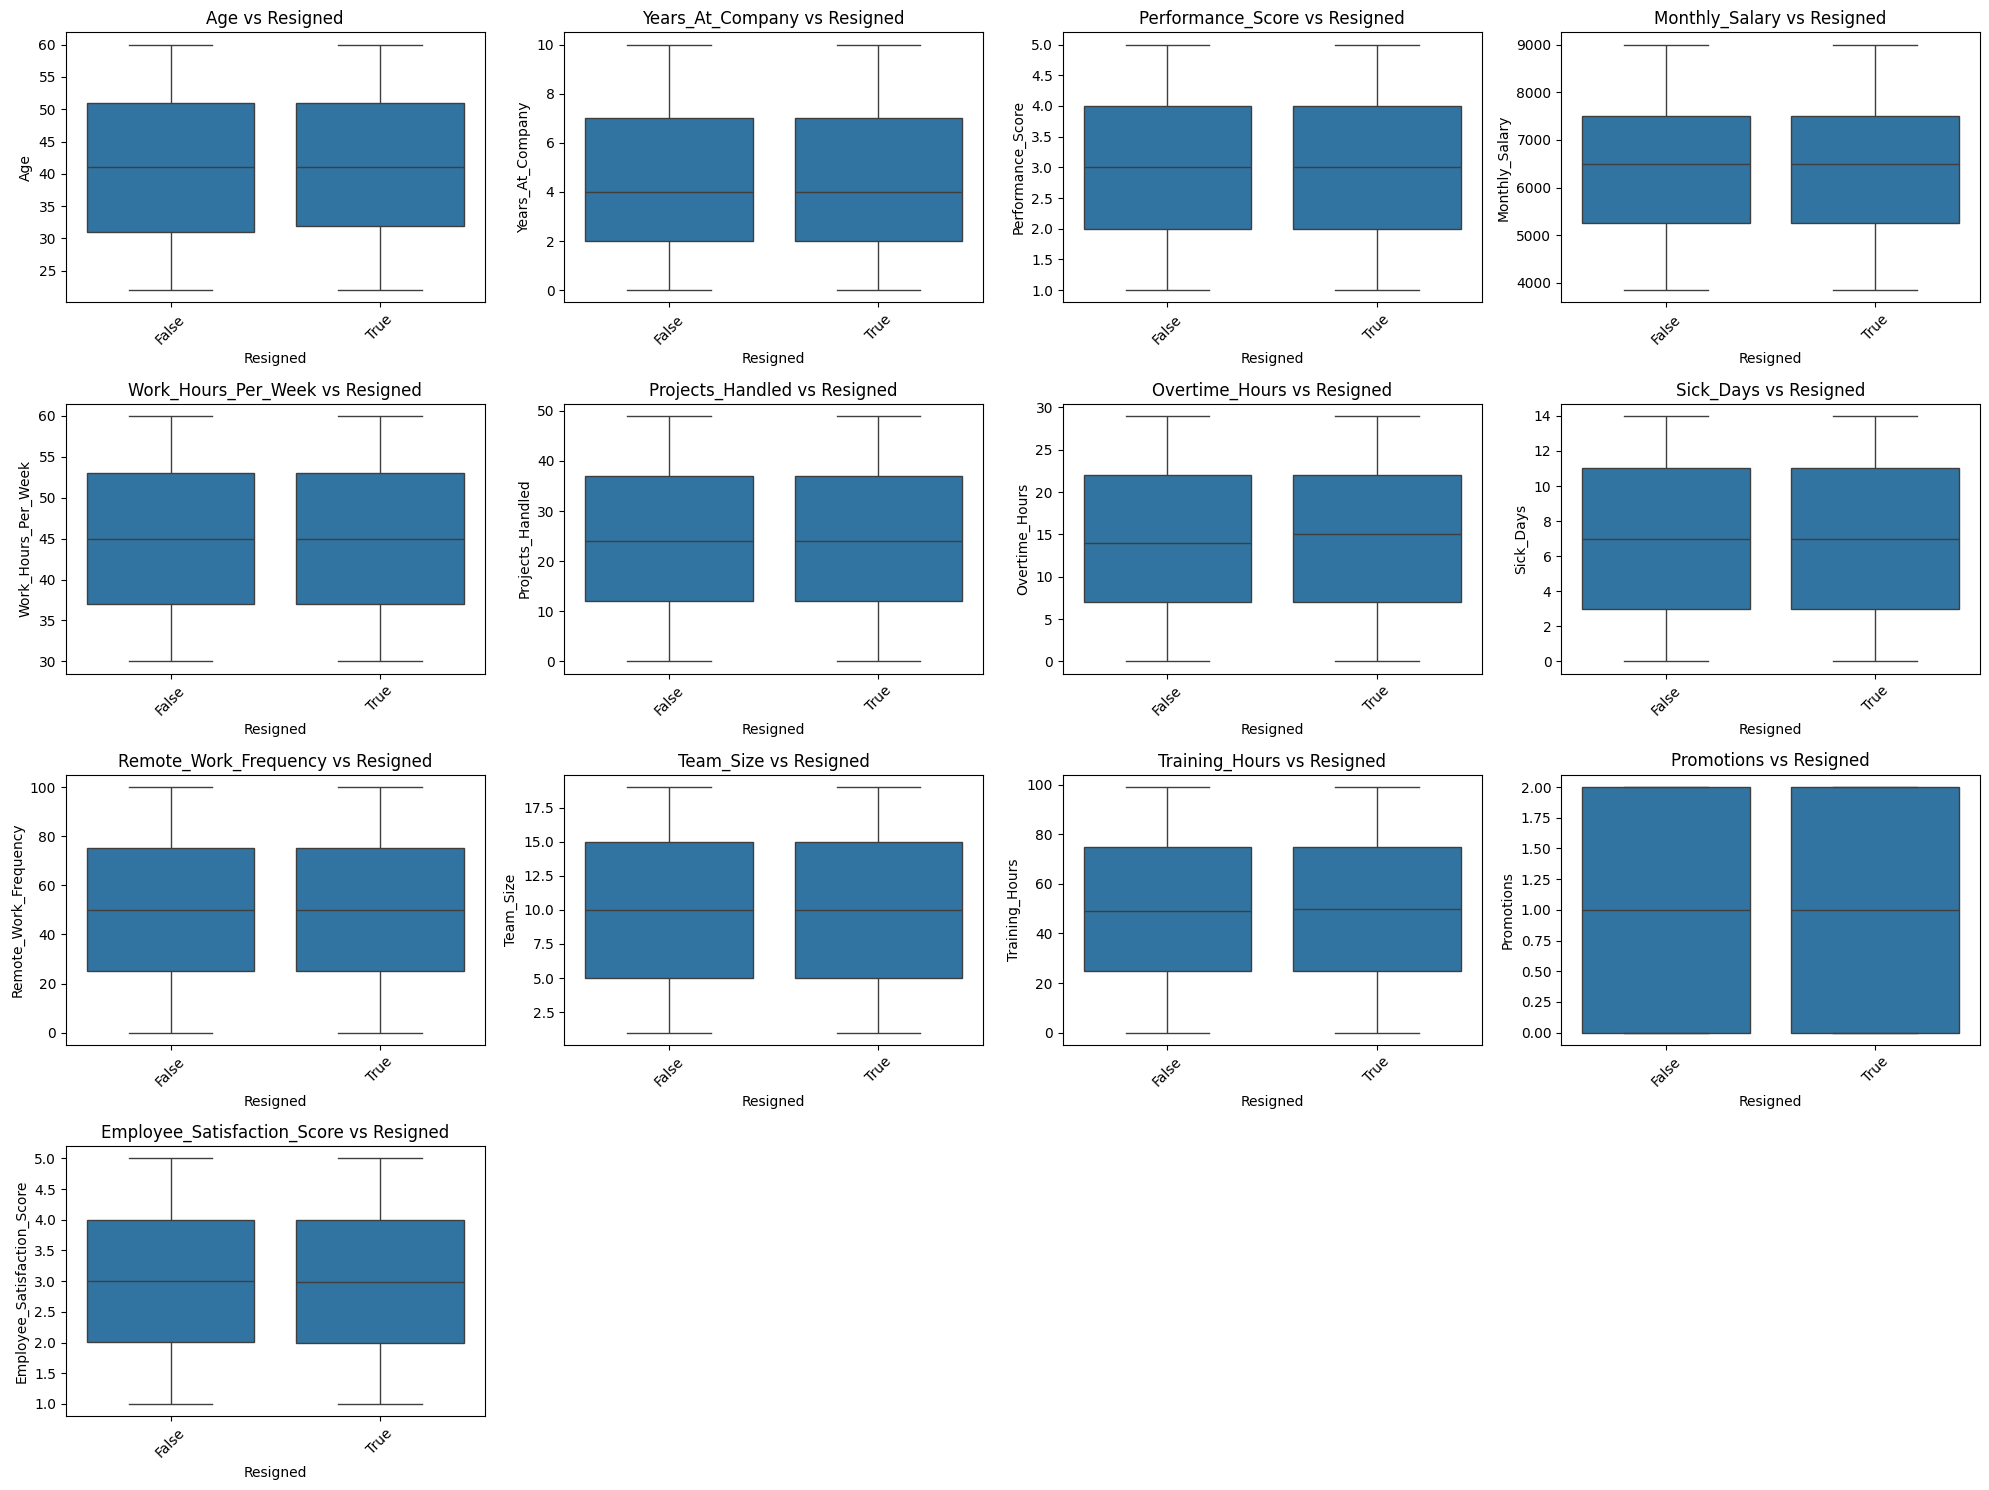

In [87]:
fig, axes = plt.subplots(4, 4, figsize=(20, 15))
axes_flat = axes.flatten()

for i, col in enumerate(NUMERIC_FEATURES):
    sns.boxplot(data=df, x=CLASSIFICATION_TARGET, y=col, ax=axes_flat[i])
    axes_flat[i].set_title(f'{col} vs {CLASSIFICATION_TARGET}')
    axes_flat[i].tick_params(axis='x', rotation=45)
for i in range(len(NUMERIC_FEATURES), 4*4):
    fig.delaxes(axes_flat[i])

plt.tight_layout()
plt.show()

In [92]:
def analyze_categorical_features(axes, df, target_col, categorical_features):
    """Анализ категориальных признаков для классификации"""
    results = []
    
    for i, col in enumerate(categorical_features):
        # Группировка и расчет % уволившихся
        grouped = df.groupby(col)[target_col].agg(['mean', 'count']).reset_index()
        grouped.columns = [col, 'Resigned_Rate', 'Count']
        grouped = grouped.sort_values('Resigned_Rate', ascending=False)
        
        # Bar plot (фикс предупреждения seaborn)
        ax = axes[i]
        sns.barplot(data=grouped, x=col, y='Resigned_Rate', ax=ax, 
                   hue=col, palette='viridis', legend=False)
        ax.set_title(f'{col}\nResigned Rate: {grouped["Resigned_Rate"].mean():.1%}')
        ax.tick_params(axis='x', rotation=45)
        ax.set_ylim(0, max(grouped['Resigned_Rate']) * 1.2)
        ax.set_xlabel('')  # Убираем дублирующую подпись оси
        
        # Добавляем количество наблюдений
        for idx, row in grouped.iterrows():
            ax.text(idx, row['Resigned_Rate'] + 0.01, f"n={row['Count']}", 
                   ha='center', fontsize=8)
        
        # Chi-square test
        from scipy.stats import chi2_contingency
        contingency = pd.crosstab(df[col], df[target_col])
        chi2, p_value, dof, expected = chi2_contingency(contingency)
        
        results.append({
            'Feature': col,
            'Chi2': chi2,
            'P-value': p_value,
            'Significant': '✅' if p_value < 0.05 else '❌',
            'Resigned_Rate_Range': f"{grouped['Resigned_Rate'].min():.1%} - {grouped['Resigned_Rate'].max():.1%}"
        })
    
    # Скрыть пустые подграфики
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    # Таблица результатов
    results_df = pd.DataFrame(results).sort_values('P-value')
    print("\n" + "="*100)
    print("СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ")
    print("="*100)
    print(results_df.to_string(index=False))
    print("="*100)
    
    return results_df

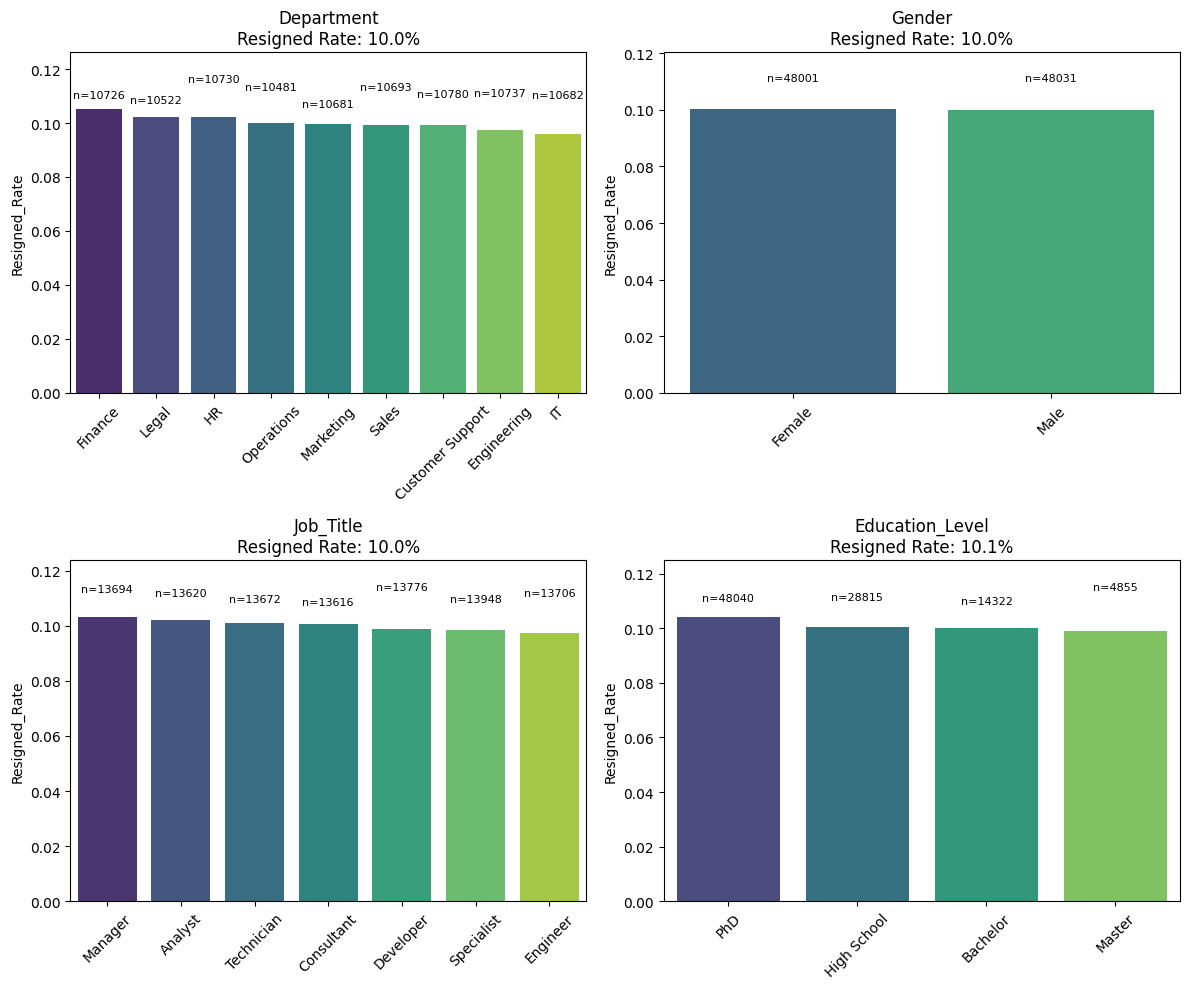


СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ
        Feature     Chi2  P-value Significant Resigned_Rate_Range
     Department 7.400879 0.494061           ❌        9.6% - 10.5%
      Job_Title 3.810262 0.702335           ❌        9.7% - 10.3%
Education_Level 1.032496 0.793389           ❌        9.9% - 10.4%
         Gender 0.013990 0.905846           ❌       10.0% - 10.0%


In [95]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

categorical_results = analyze_categorical_features(axes, df, 'Resigned', NOMINAL_FEATURES)

# Задание №3. Коррелляционный анализ

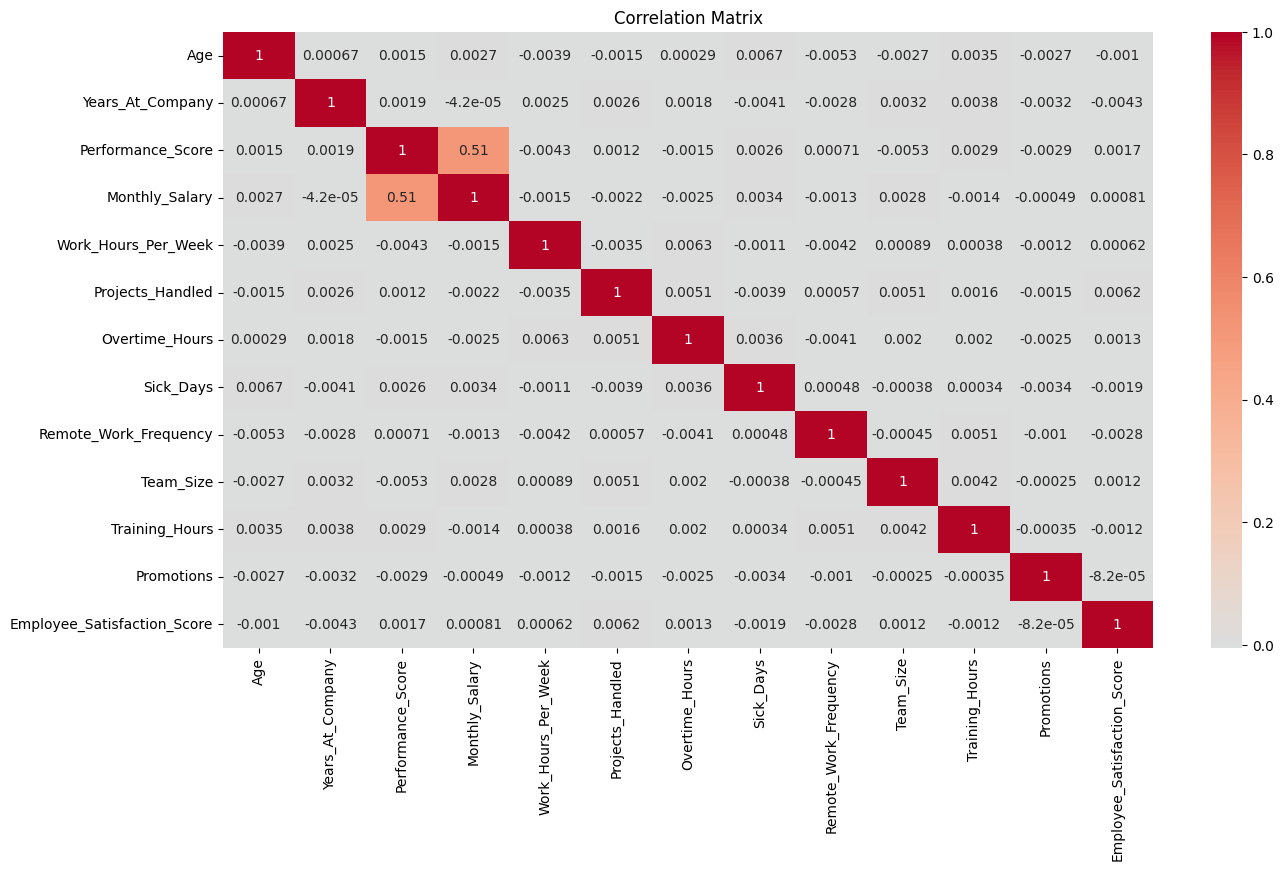

In [69]:
plt.figure(figsize=(15, 8))
sns.heatmap(df[NUMERIC_FEATURES].corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

# Задание №4. Регресионный анализ

In [72]:
def simple_linear_regression(df, col1, col2, test_size=0.2):
    results = []
    
    for y_col, x_col in [(col1, col2), (col2, col1)]:
        X = df[[x_col]].values
        y = df[y_col].values
        
        # Train/test split
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=42
        )
        
        # Модель
        model = LinearRegression()
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        # Метрики
        results.append({
            'Модель': f'{y_col} ~ {x_col}',
            'R²': r2_score(y_test, y_pred),
            'MSE': mean_squared_error(y_test, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
            'Коэффициент': model.coef_[0],
            'Intercept': model.intercept_
        })
        
        # Визуализация
        plt.scatter(X_test, y_test, alpha=0.3, s=10, label='Test')
        plt.plot(X_test, y_pred, color='red', linewidth=2, label='Prediction')
        plt.xlabel(x_col)
        plt.ylabel(y_col)
        plt.title(f'{y_col} ~ {x_col}\nR² = {r2_score(y_test, y_pred):.4f}')
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()
    
    return pd.DataFrame(results)

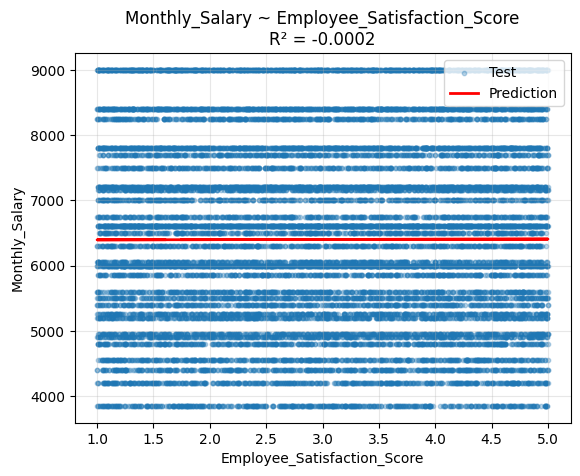

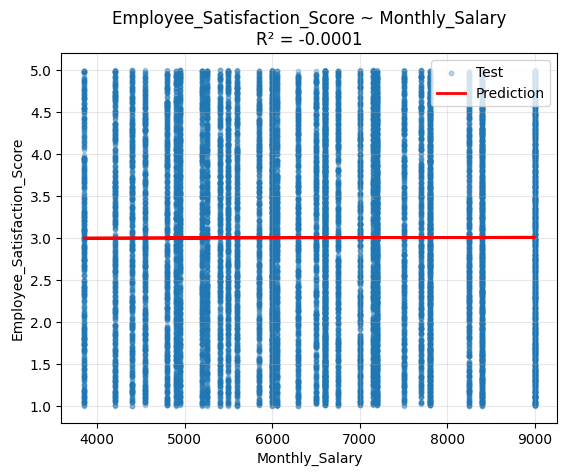

,Модель,R²,MSE,RMSE,Коэффициент,Intercept
0,Monthly_Salary ~ Employee_Satisfaction_Score,-0.000186,1.891910e+06,1375.467342,2.908760,6390.612215
1,Employee_Satisfaction_Score ~ Monthly_Salary,-0.000061,1.332312e+00,1.154258,0.000002,2.987658


In [73]:
# Использование
metrics_table = simple_linear_regression(df, MAIN_FEATURE, REGRESSION_TARGET)
metrics_table

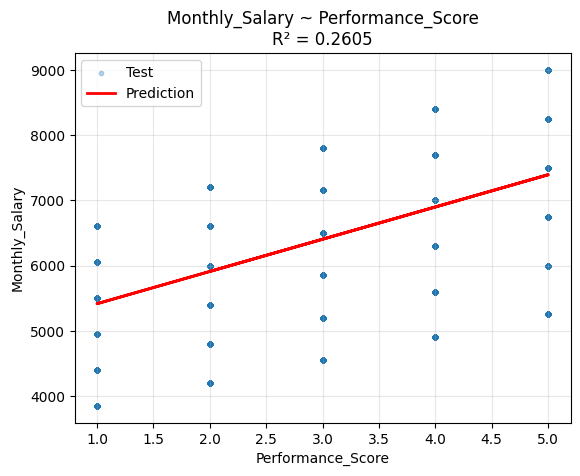

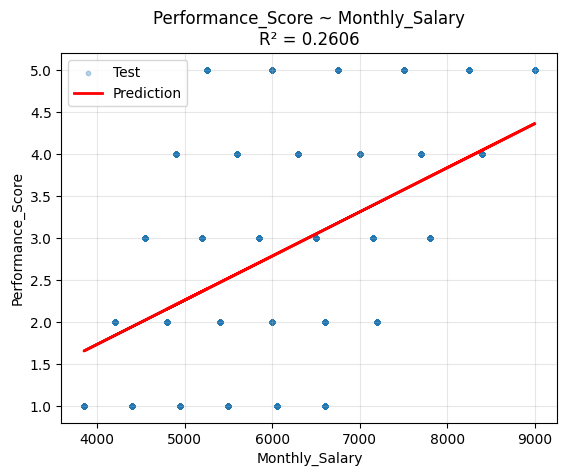

,Модель,R²,MSE,RMSE,Коэффициент,Intercept
0,Monthly_Salary ~ Performance_Score,0.260508,1.398793e+06,1182.705875,494.019260,4920.883980
1,Performance_Score ~ Monthly_Salary,0.260570,1.482115e+00,1.217422,0.000526,-0.371616


In [74]:
metrics_table = simple_linear_regression(df, MAIN_FEATURE, 'Performance_Score')
metrics_table

# Создание классификатора

In [16]:
def evaluate_model(y_true, y_pred, y_proba, model_name):
    """Расчет всех метрик"""
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-score': f1_score(y_true, y_pred, zero_division=0),
        'AUC': auc(*roc_curve(y_true, y_proba)[:2]),
        'y_true': y_true,
        'y_pred': y_pred,
        'y_proba': y_proba
    }

def plot_confusion_matrix(y_true, y_pred, model_name, ax):
    """Матрица ошибок на одной оси"""
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'{model_name}\nConfusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

def plot_roc_curve(y_true, y_proba, model_name, ax):
    """ROC-кривая на одной оси"""
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f'{model_name} (AUC={roc_auc:.3f})', linewidth=2)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('ROC Curve')
    ax.legend()
    ax.grid(alpha=0.3)

In [17]:
def build_logistic_regression(X_train, y_train, X_test, y_test):
    """Логистическая регрессия + SMOTE"""
    smote = SMOTE(random_state=42)
    X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
    
    model = LogisticRegression(random_state=42, max_iter=1000)
    model.fit(X_train_bal, y_train_bal)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba, 'Logistic Regression')

def build_decision_tree(X_train, y_train, X_test, y_test):
    """Дерево решений + SMOTE"""
    smote = SMOTE(random_state=42)
    X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
    
    model = DecisionTreeClassifier(random_state=42, max_depth=5)
    model.fit(X_train_bal, y_train_bal)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba, 'Decision Tree')

def build_neural_network(X_train, y_train, X_test, y_test):
    """Нейронная сеть + SMOTE"""
    smote = SMOTE(random_state=42)
    X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_bal)
    X_test_scaled = scaler.transform(X_test)
    
    model = MLPClassifier(hidden_layer_sizes=(50, 25), random_state=42, max_iter=500)
    model.fit(X_train_scaled, y_train_bal)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba, 'Neural Network')

In [105]:
def run_classification(df, feature_cols, target_col, nominal_cols=None):
    """Запуск всех моделей и визуализация с поддержкой категориальных признаков"""
    
    # One-Hot Encoding для категориальных признаков
    if nominal_cols:
        numeric_cols = [col for col in feature_cols if col not in nominal_cols]
        X_numeric = df[numeric_cols].values
        
        # One-Hot Encoding
        encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
        X_categorical = encoder.fit_transform(df[nominal_cols])
        
        # Объединение признаков
        X = np.hstack([X_numeric, X_categorical])
        
        # Имена признаков для интерпретации
        numeric_feature_names = numeric_cols
        cat_feature_names = encoder.get_feature_names_out(nominal_cols)
        feature_names = numeric_feature_names + list(cat_feature_names)
    else:
        X = df[feature_cols].values
        feature_names = feature_cols
    
    y = df[target_col].values
    
    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    
    # Запуск моделей
    results = [
        build_logistic_regression(X_train, y_train, X_test, y_test),
        build_decision_tree(X_train, y_train, X_test, y_test),
        build_neural_network(X_train, y_train, X_test, y_test)
    ]
    
    # Таблица метрик
    metrics_df = pd.DataFrame(results).drop(columns=['y_true', 'y_pred', 'y_proba'])
    print("\n" + "="*70)
    print("СРАВНЕНИЕ МОДЕЛЕЙ")
    print("="*70)
    print(metrics_df.to_string(index=False))
    print("="*70)
    
    if nominal_cols:
        print(f"\n📊 Использовано признаков: {len(feature_names)}")
        print(f"   Числовые: {len(numeric_cols)}")
        print(f"   Категориальные (после encoding): {len(cat_feature_names)}")
    
    # Визуализация
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Матрицы ошибок (3 модели)
    for i, res in enumerate(results):
        ax = axes[i//2, i%2] if i < 3 else axes[1, 1]
        plot_confusion_matrix(res['y_true'], res['y_pred'], res['Model'], ax)
    
    # ROC-кривые (все на одном графике)
    axes[1, 1].clear()
    for res in results:
        plot_roc_curve(res['y_true'], res['y_proba'], res['Model'], axes[1, 1])
    
    plt.tight_layout()
    plt.show()
    
    # Лучшая модель по F1-score
    best = metrics_df.loc[metrics_df['F1-score'].idxmax()]
    print(f"\n🏆 Лучшая модель по F1-score: {best['Model']} (F1={best['F1-score']:.4f})")
    
    return results, metrics_df

In [102]:
df.shape

(96032, 19)

C:\Users\frlfff\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



СРАВНЕНИЕ МОДЕЛЕЙ
              Model  Accuracy  Precision   Recall  F1-score      AUC
Logistic Regression  0.493362   0.099692 0.504935  0.166510 0.495390
      Decision Tree  0.899776   0.000000 0.000000  0.000000 0.488083
     Neural Network  0.782007   0.103714 0.153766  0.123875 0.496635


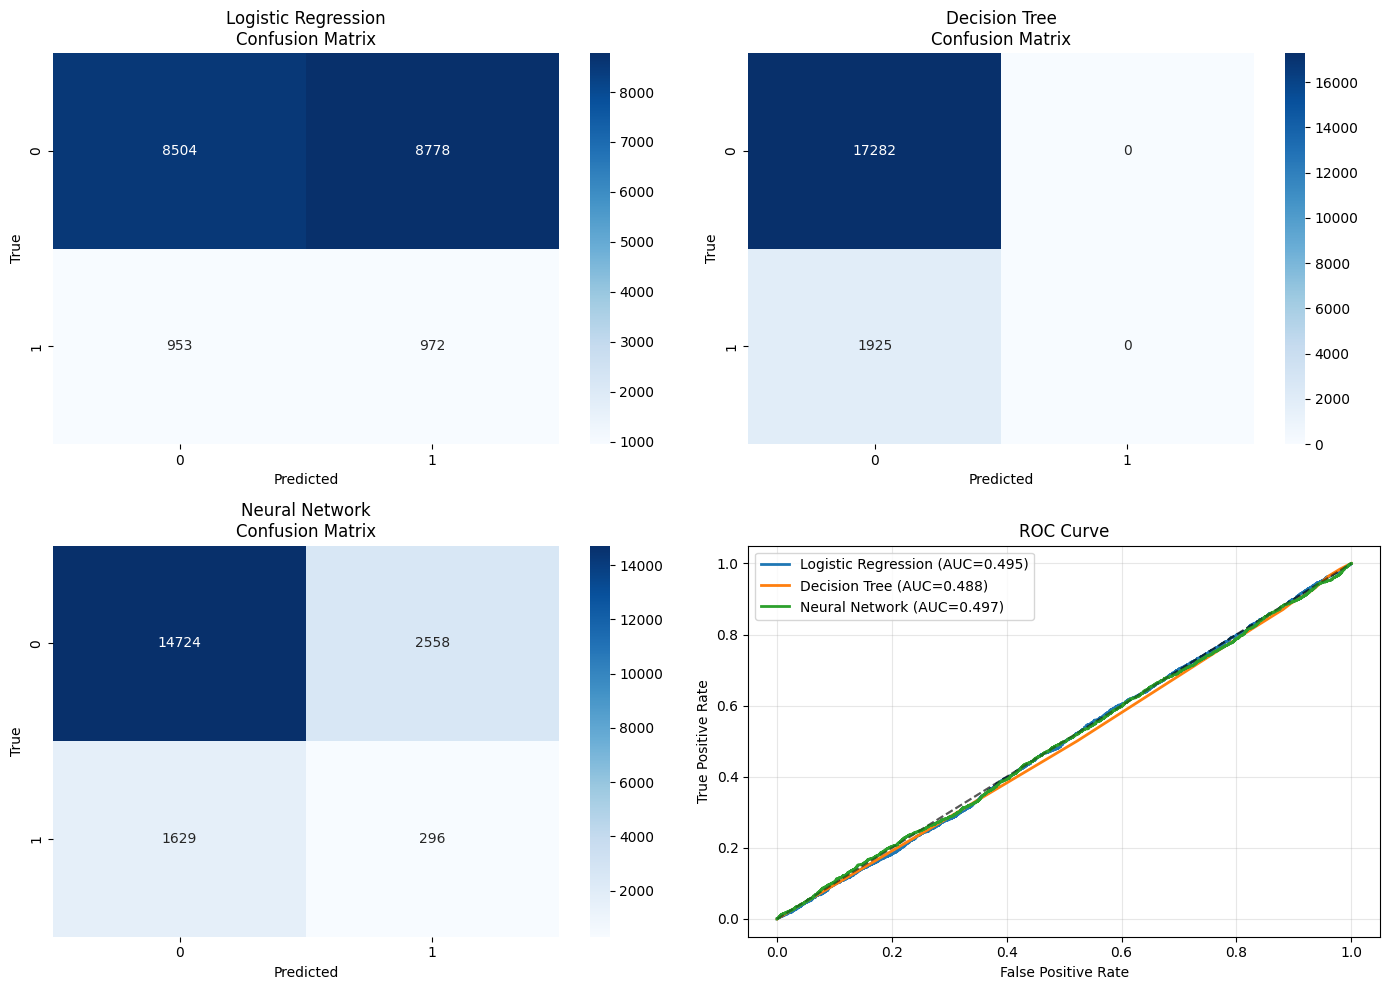


🏆 Лучшая модель по F1-score: Logistic Regression (F1=0.1665)


,Model,Accuracy,Precision,Recall,F1-score,AUC
0,Logistic Regression,0.493362,0.099692,0.504935,0.166510,0.495390
1,Decision Tree,0.899776,0.000000,0.000000,0.000000,0.488083
2,Neural Network,0.782007,0.103714,0.153766,0.123875,0.496635


In [107]:
results, metrics = run_classification(df, NUMERIC_FEATURES, CLASSIFICATION_TARGET) #, nominal_cols=NOMINAL_FEATURES)

metrics

# Дисперсионный анализ

In [117]:
def run_anova(df, numeric_col, group_col, alpha=0.05):
    """ANOVA с проверкой предпосылок"""
    
    # Группировка данных
    groups = [group[numeric_col].dropna() for name, group in df.groupby(group_col)]
    group_names = list(df[group_col].unique())
    
    print("="*70)
    print(f"ANOVA: {numeric_col} по группам '{group_col}'")
    print("="*70)
    print(f"Null hypothesis H₀: Средние значения {numeric_col} одинаковы во всех группах")
    print(f"Alternative hypothesis H₁: Хотя бы одно среднее отличается")
    print("="*70)
    
    # Описательная статистика
    print("\n📊 Описательная статистика:")
    desc = df.groupby(group_col)[numeric_col].agg(['count', 'mean', 'std', 'median'])
    print(desc.to_string())
    
    # Визуализация распределений
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    sns.boxplot(data=df, x=group_col, y=numeric_col, ax=axes[0], 
               hue=group_col, palette='viridis', legend=False)
    axes[0].set_title('Распределение по группам')
    axes[0].tick_params(axis='x', rotation=45)
    
    sns.violinplot(data=df, x=group_col, y=numeric_col, ax=axes[1], 
                  hue=group_col, palette='viridis', legend=False, inner='box')
    axes[1].set_title('Плотность распределения')
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()
    
    # Проверка предпосылок
    print("\n🔍 Проверка предпосылок ANOVA:")
    
    # 1. Нормальность (Шапиро-Уилк для каждой группы)
    print("\n1️⃣ Нормальность распределения (тест Шапиро-Уилк):")
    normality_results = []
    for name, group in zip(group_names, groups):
        if len(group) <= 5000:
            stat, p = shapiro(group)
        else:
            stat, p = stats.normaltest(group)
        normality_results.append({'Group': str(name), 'Statistic': stat, 'P-value': p, 'Normal': p > alpha})
        print(f"   {str(name):15s}: W={stat:.4f}, p={p:.4f} → {'✅ Нормальное' if p > alpha else '❌ Не нормальное'}")
    
    normality_df = pd.DataFrame(normality_results)
    all_normal = normality_df['Normal'].all()
    
    # 2. Гомогенность дисперсий (тест Левена)
    print(f"\n2️⃣ Однородность дисперсий (тест Левена, α={alpha}):")
    levene_stat, levene_p = levene(*groups)
    homogenous = levene_p > alpha
    print(f"   W={levene_stat:.4f}, p={levene_p:.4f} → {'✅ Дисперсии однородны' if homogenous else '❌ Дисперсии неоднородны'}")
    
    # Выбор теста
    print("\n" + "="*70)
    if all_normal and homogenous:
        print("✅ Предпосылки ANOVA выполнены → используем параметрический тест")
        f_stat, p_value = f_oneway(*groups)
        test_used = 'ANOVA (F-test)'
    else:
        print("⚠️ Предпосылки нарушены → используем непараметрический тест Крускала-Уоллиса")
        h_stat, p_value = kruskal(*groups)
        f_stat = h_stat
        test_used = 'Kruskal-Wallis H-test'
    
    # Результаты
    print(f"\n📈 Результаты {test_used}:")
    print(f"   F/H-статистика: {f_stat:.4f}")
    print(f"   P-value:        {p_value:.4f}")
    print(f"   Alpha:          {alpha}")
    print(f"   → {'✅ ОТКЛОНИТЬ H₀ (различия значимы)' if p_value < alpha else '❌ НЕ ОТКЛОНИТЬ H₀ (различий нет)'}")
    
    # Размер эффекта
    if all_normal and homogenous:
        ss_between = sum(len(g) * (np.mean(g) - np.mean(np.concatenate(groups)))**2 for g in groups)
        ss_total = sum((x - np.mean(np.concatenate(groups)))**2 for g in groups for x in g)
        eta_squared = ss_between / ss_total if ss_total > 0 else 0
        print(f"   η² (размер эффекта): {eta_squared:.4f} → ", end='')
        if eta_squared < 0.01:
            print("очень слабый эффект")
        elif eta_squared < 0.06:
            print("слабый эффект")
        elif eta_squared < 0.14:
            print("средний эффект")
        else:
            print("сильный эффект")
    
    print("="*70)
    
    return {
        'test_used': test_used,
        'statistic': f_stat,
        'p_value': p_value,
        'reject_h0': p_value < alpha,
        'normality': normality_df,
        'homogeneity_p': levene_p,
        'eta_squared': eta_squared if all_normal and homogenous else None
    }

ANOVA: Monthly_Salary по группам 'Resigned'
Null hypothesis H₀: Средние значения Monthly_Salary одинаковы во всех группах
Alternative hypothesis H₁: Хотя бы одно среднее отличается

📊 Описательная статистика:
          count         mean          std  median
Resigned                                         
False     86409  6403.548242  1372.157709  6500.0
True       9623  6395.417230  1368.680766  6500.0


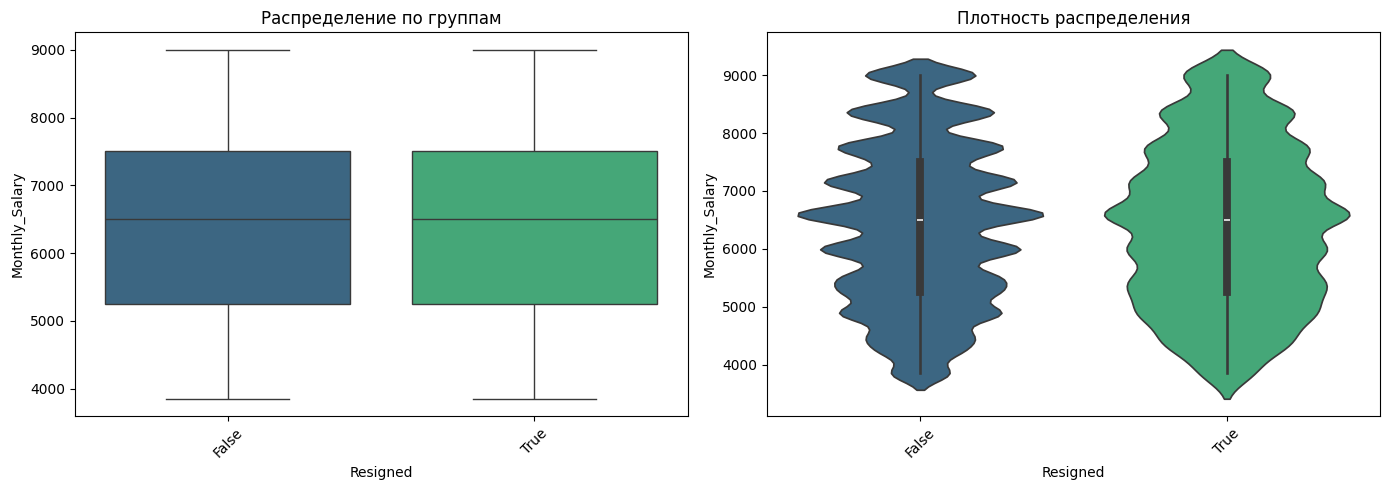


🔍 Проверка предпосылок ANOVA:

1️⃣ Нормальность распределения (тест Шапиро-Уилк):
   True           : W=10510.6723, p=0.0000 → ❌ Не нормальное
   False          : W=1262.5494, p=0.0000 → ❌ Не нормальное

2️⃣ Однородность дисперсий (тест Левена, α=0.05):
   W=0.0021, p=0.9636 → ✅ Дисперсии однородны

⚠️ Предпосылки нарушены → используем непараметрический тест Крускала-Уоллиса

📈 Результаты Kruskal-Wallis H-test:
   F/H-статистика: 0.3215
   P-value:        0.5707
   Alpha:          0.05
   → ❌ НЕ ОТКЛОНИТЬ H₀ (различий нет)


In [118]:
result = run_anova(df, numeric_col='Monthly_Salary', group_col='Resigned')